In [1]:
import sys
sys.path.append("../src")

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import Ridge, Lasso
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score
from category_encoders import OneHotEncoder

In [2]:
from wrangle import clean_files

df = clean_files("../data/raw/buenos-aires-real-estate-*.csv")

target_col = "price_aprox_usd"
feature_cols = [col for col in df.columns if col != target_col]

X = df[feature_cols]
y = df[target_col]

print(f"Features shape: {X.shape}")
print(f"Target shape: {y.shape}")
print(f"Feature columns: {X.columns.tolist()}")
print(f"Unique neighborhoods: {X['neighborhood'].nunique()}")

Features shape: (6247, 4)
Target shape: (6247,)
Feature columns: ['surface_covered_in_m2', 'lat', 'lon', 'neighborhood']
Unique neighborhoods: 56


In [3]:
X_train_3, X_test_3, y_train_3, y_test_3 = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"Training set: {X_train_3.shape[0]} samples")
print(f"Test set: {X_test_3.shape[0]} samples")

Training set: 4997 samples
Test set: 1250 samples


In [4]:
model_ridge_3 = make_pipeline(
    OneHotEncoder(use_cat_names=True),
    StandardScaler(),
    Ridge(alpha=1.0)
)

model_ridge_3

/workspaces/Buenos_Aires_price_prediction_using_Linear_Regression/.venv/lib/python3.12/site-packages/sklearn/externals/_numpydoc/docscrape.py:420: UserWarning: Unknown section Example
  self[section] = content


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('onehotencoder', ...), ('standardscaler', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,use_cat_names,True
,verbose,0
,cols,None
,drop_invariant,False
,return_df,True
,handle_missing,'value'
,handle_unknown,'value'


In [5]:
model_ridge_3.fit(X_train_3, y_train_3)

y_pred_ridge_train = model_ridge_3.predict(X_train_3)
y_pred_ridge_test = model_ridge_3.predict(X_test_3)

rmse_ridge_train = root_mean_squared_error(y_train_3, y_pred_ridge_train)
rmse_ridge_test = root_mean_squared_error(y_test_3, y_pred_ridge_test)

print(f"Ridge Training RMSE: ${rmse_ridge_train:,.2f}")
print(f"Ridge Test RMSE: ${rmse_ridge_test:,.2f}")
print(f"Ridge Test MAE: ${mean_absolute_error(y_test_3, y_pred_ridge_test):,.2f}")
print(f"Ridge Test R²: {r2_score(y_test_3, y_pred_ridge_test):.4f}")

Ridge Training RMSE: $33,174.63
Ridge Test RMSE: $36,971.20
Ridge Test MAE: $26,441.06
Ridge Test R²: 0.6330


In [6]:
encoded = model_ridge_3[:-1].transform(X_train_3)
print(encoded.shape)
print(model_ridge_3[0].get_feature_names_out()[:8])

(4997, 59)
['surface_covered_in_m2' 'lat' 'lon' 'neighborhood_Constitución'
 'neighborhood_Caballito' 'neighborhood_Flores' 'neighborhood_Belgrano'
 'neighborhood_Recoleta']


In [7]:
model_lasso_3 = make_pipeline(
    OneHotEncoder(use_cat_names=True),
    StandardScaler(),
    Lasso(alpha=100, max_iter=10000)
)

model_lasso_3.fit(X_train_3, y_train_3)

y_pred_lasso_train = model_lasso_3.predict(X_train_3)
y_pred_lasso_test = model_lasso_3.predict(X_test_3)

rmse_lasso_train = root_mean_squared_error(y_train_3, y_pred_lasso_train)
rmse_lasso_test = root_mean_squared_error(y_test_3, y_pred_lasso_test)

print(f"Lasso Training RMSE: ${rmse_lasso_train:,.2f}")
print(f"Lasso Test RMSE: ${rmse_lasso_test:,.2f}")
print(f"Lasso Test MAE: ${mean_absolute_error(y_test_3, y_pred_lasso_test):,.2f}")
print(f"Lasso Test R²: {r2_score(y_test_3, y_pred_lasso_test):.4f}")

lasso_coefs = pd.Series(
    model_lasso_3[-1].coef_,
    index=model_lasso_3[0].get_feature_names_out(),
)
print(f"Non-zero coefficients: {(lasso_coefs != 0).sum()} of {len(lasso_coefs)}")
print(f"Zeroed-out features: {(lasso_coefs == 0).sum()}")

Lasso Training RMSE: $33,195.81
Lasso Test RMSE: $36,916.38
Lasso Test MAE: $26,329.42
Lasso Test R²: 0.6341
Non-zero coefficients: 51 of 59
Zeroed-out features: 8


In [8]:
print(lasso_coefs[lasso_coefs == 0].index.tolist())

['neighborhood_Saavedra', 'neighborhood_Villa del Parque', 'neighborhood_Abasto', 'neighborhood_Villa General Mitre', 'neighborhood_Villa Real', 'neighborhood_Parque Avellaneda', 'neighborhood_Chacarita', 'neighborhood_']


In [9]:
alphas = [0.001, 0.01, 0.1, 1, 10, 100, 1000, 10000, 100000, 1000000]
ridge_results = []

for a in alphas:
    model = make_pipeline(
        OneHotEncoder(use_cat_names=True),
        StandardScaler(),
        Ridge(alpha=a)
    )
    model.fit(X_train_3, y_train_3)

    rmse_train = root_mean_squared_error(y_train_3, model.predict(X_train_3))
    rmse_test = root_mean_squared_error(y_test_3, model.predict(X_test_3))

    ridge_results.append({"alpha": a, "rmse_train": rmse_train, "rmse_test": rmse_test})

df_ridge_results = pd.DataFrame(ridge_results)
print(df_ridge_results)

         alpha    rmse_train     rmse_test
0        0.001  33174.627686  36971.857963
1        0.010  33174.627686  36971.852000
2        0.100  33174.627709  36971.792414
3        1.000  33174.630059  36971.200624
4       10.000  33174.857341  36965.674667
5      100.000  33192.565525  36939.565183
6     1000.000  34066.133694  37638.241670
7    10000.000  45363.746872  48137.509999
8   100000.000  56602.479662  58906.292083
9  1000000.000  58590.146991  60828.658590


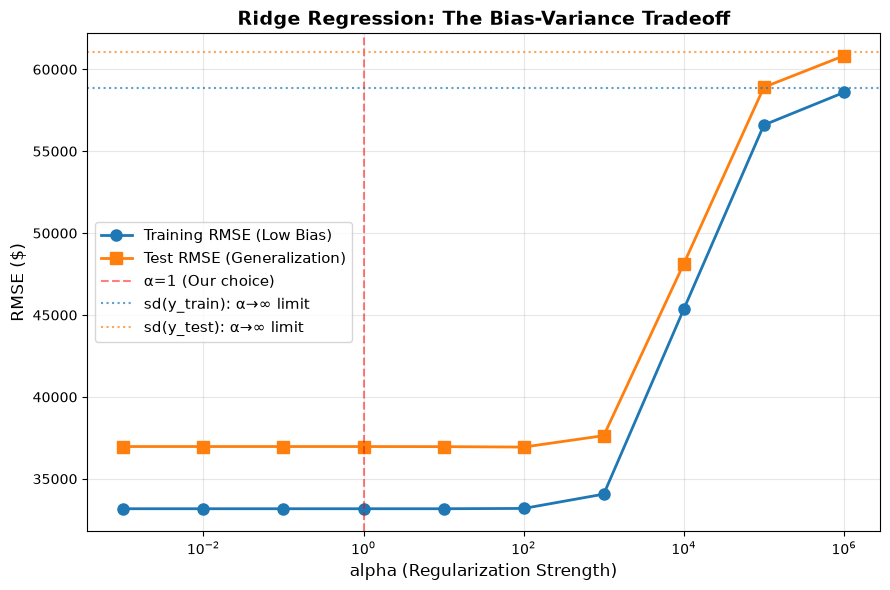

In [10]:
fig, ax = plt.subplots(figsize=(9, 6))
ax.plot(df_ridge_results["alpha"], df_ridge_results["rmse_train"],
        marker='o', linewidth=2, markersize=8, label="Training RMSE (Low Bias)")
ax.plot(df_ridge_results["alpha"], df_ridge_results["rmse_test"],
        marker='s', linewidth=2, markersize=8, label="Test RMSE (Generalization)")
ax.axvline(x=1, color='red', linestyle='--', alpha=0.5, label="α=1 (Our choice)")

ax.axhline(y_train_3.std(), color='C0', linestyle=':', alpha=0.7, label="sd(y_train): α→∞ limit")
ax.axhline(y_test_3.std(), color='C1', linestyle=':', alpha=0.7, label="sd(y_test): α→∞ limit")
ax.set_xlabel("alpha (Regularization Strength)", fontsize=12)
ax.set_ylabel("RMSE ($)", fontsize=12)
ax.set_xscale("log")
ax.set_title("Ridge Regression: The Bias-Variance Tradeoff", fontsize=14, fontweight='bold')
ax.legend(fontsize=11)
ax.grid(True, alpha=0.3)
plt.tight_layout()
fig.savefig("../reports/figures/ridge_alpha_curve.png", dpi=150, bbox_inches="tight")
plt.show()

In [11]:
lasso_results = []
alphas_lasso = [0.1, 1, 10, 100, 1000]

for a in alphas_lasso:
    model = make_pipeline(
        OneHotEncoder(use_cat_names=True),
        StandardScaler(),
        Lasso(alpha=a, max_iter=10000)
    )
    model.fit(X_train_3, y_train_3)

    rmse_train = root_mean_squared_error(y_train_3, model.predict(X_train_3))
    rmse_test = root_mean_squared_error(y_test_3, model.predict(X_test_3))
    non_zero_features = (model.named_steps["lasso"].coef_ != 0).sum()

    lasso_results.append({
        "alpha": a,
        "rmse_train": rmse_train,
        "rmse_test": rmse_test,
        "non_zero_features": non_zero_features
    })

df_lasso_results = pd.DataFrame(lasso_results)
print(df_lasso_results)

/workspaces/Buenos_Aires_price_prediction_using_Linear_Regression/.venv/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.194194e+11, tolerance: 1.729e+09
  model = cd_fast.enet_coordinate_descent(


    alpha    rmse_train     rmse_test  non_zero_features
0     0.1  33174.627717  36971.752453                 59
1     1.0  33174.630810  36970.863141                 57
2    10.0  33174.940327  36962.125344                 57
3   100.0  33195.812467  36916.381945                 51
4  1000.0  33784.712145  37290.560830                 29


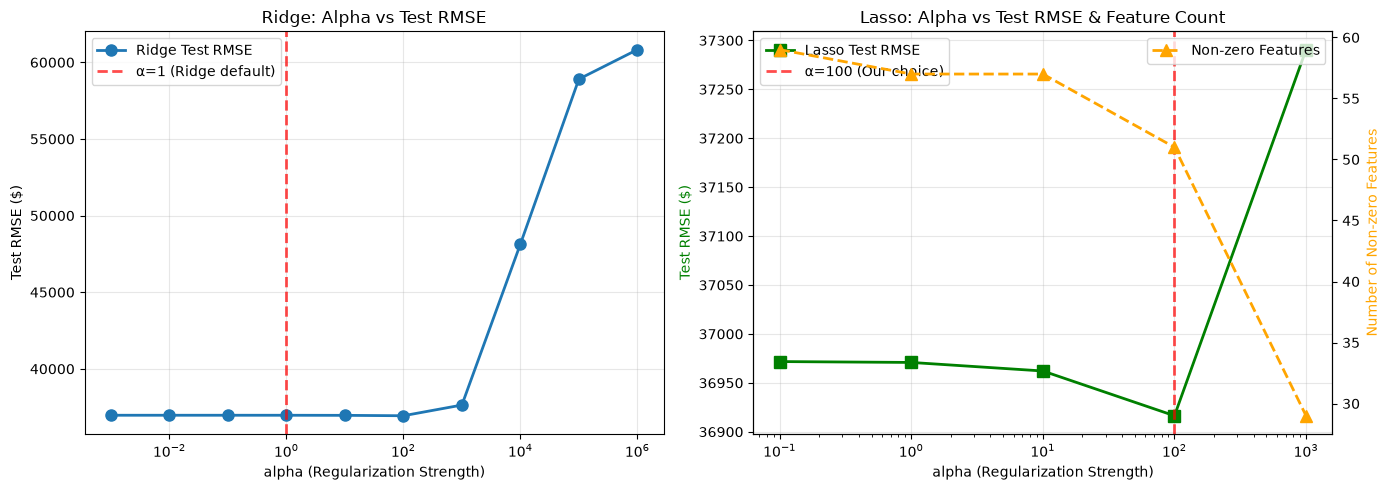

In [12]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(df_ridge_results["alpha"], df_ridge_results["rmse_test"],
         marker='o', linewidth=2, markersize=8, label="Ridge Test RMSE")
ax1.axvline(x=1, color='red', linestyle='--', alpha=0.7, linewidth=2, label="α=1 (Ridge default)")
ax1.set_xlabel("alpha (Regularization Strength)")
ax1.set_ylabel("Test RMSE ($)")
ax1.set_xscale("log")
ax1.set_title("Ridge: Alpha vs Test RMSE")
ax1.legend()
ax1.grid(True, alpha=0.3)

ax2_twin = ax2.twinx()
ax2.plot(df_lasso_results["alpha"], df_lasso_results["rmse_test"],
         marker='s', linewidth=2, markersize=8, color='green', label="Lasso Test RMSE")
ax2_twin.plot(df_lasso_results["alpha"], df_lasso_results["non_zero_features"],
              marker='^', linewidth=2, markersize=8, color='orange', linestyle='--', label="Non-zero Features")
ax2.axvline(x=100, color='red', linestyle='--', alpha=0.7, linewidth=2, label="α=100 (Our choice)")
ax2.set_xlabel("alpha (Regularization Strength)")
ax2.set_ylabel("Test RMSE ($)", color='green')
ax2_twin.set_ylabel("Number of Non-zero Features", color='orange')
ax2.set_xscale("log")
ax2.set_title("Lasso: Alpha vs Test RMSE & Feature Count")
ax2.legend(loc='upper left')
ax2_twin.legend(loc='upper right')
ax2.grid(True, alpha=0.3)

plt.tight_layout()
fig.savefig("../reports/figures/alpha_sweeps.png", dpi=150, bbox_inches="tight")
plt.show()

In [13]:
import warnings

for a in [0.1, 1, 10, 100, 1000]:
    with warnings.catch_warnings(record=True) as w:
        warnings.simplefilter("always")
        m = make_pipeline(OneHotEncoder(use_cat_names=True), StandardScaler(),
                          Lasso(alpha=a, max_iter=10000))
        m.fit(X_train_3, y_train_3)
    print(a, "did not converge" if w else "converged")

0.1 did not converge
1 did not converge
10 did not converge
100 did not converge
1000 did not converge


In [14]:
from sklearn.linear_model import RidgeCV, LassoCV

ridge_cv_model = make_pipeline(
    OneHotEncoder(use_cat_names=True),
    StandardScaler(),
    RidgeCV(alphas=[0.001, 0.01, 0.1, 1, 10, 100, 1000, 10000, 100000, 1000000], cv=5)
)
ridge_cv_model.fit(X_train_3, y_train_3)

optimal_alpha_ridge = ridge_cv_model.named_steps["ridgecv"].alpha_
pred_ridge_cv = ridge_cv_model.predict(X_test_3)
print(f"RidgeCV selected alpha: {optimal_alpha_ridge}")
print(f"Ridge CV Test RMSE: ${root_mean_squared_error(y_test_3, pred_ridge_cv):,.2f}")
print(f"Ridge CV Test MAE:  ${mean_absolute_error(y_test_3, pred_ridge_cv):,.2f}")
print(f"Ridge CV Test R²:   {r2_score(y_test_3, pred_ridge_cv):.4f}")

lasso_cv_model = make_pipeline(
    OneHotEncoder(use_cat_names=True),
    StandardScaler(),
    LassoCV(alphas=[0.1, 1, 10, 100, 1000], cv=5, max_iter=10000)
)
lasso_cv_model.fit(X_train_3, y_train_3)

optimal_alpha_lasso = lasso_cv_model.named_steps["lassocv"].alpha_
pred_lasso_cv = lasso_cv_model.predict(X_test_3)
print(f"\nLassoCV selected alpha: {optimal_alpha_lasso}")
print(f"Lasso CV Test RMSE: ${root_mean_squared_error(y_test_3, pred_lasso_cv):,.2f}")
print(f"Lasso CV Test MAE:  ${mean_absolute_error(y_test_3, pred_lasso_cv):,.2f}")
print(f"Lasso CV Test R²:   {r2_score(y_test_3, pred_lasso_cv):.4f}")
print(f"Non-zero features (Lasso CV): {(lasso_cv_model.named_steps['lassocv'].coef_ != 0).sum()}")

RidgeCV selected alpha: 10.0
Ridge CV Test RMSE: $36,965.67
Ridge CV Test MAE:  $26,429.46
Ridge CV Test R²:   0.6331

LassoCV selected alpha: 100.0
Lasso CV Test RMSE: $36,916.38
Lasso CV Test MAE:  $26,329.42
Lasso CV Test R²:   0.6341
Non-zero features (Lasso CV): 51
